In [45]:
from langchain_ollama import ChatOllama
from rag_flow import RAGFlow
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from deepeval.metrics import AnswerRelevancyMetric
from deepeval.test_case import LLMTestCase
from deepeval.models import OllamaModel



The goal of this file is to evaluate the final answer of the RAG system by testing it with different parameter combination.

In [117]:
test_data = pd.read_csv("../component_level_eval/test_data/arxiv_classifier_300_questions.csv")
questions = (
    test_data.loc[test_data["label"] == "arxiv", ["question"]]
    .dropna(subset=["question"])
    .reset_index(drop=True)
)
questions.head(3)

,question
0,What are the main limitations of economic grow...
1,What are the main limitations of operating sys...
2,How can researchers evaluate optical interfere...


In [3]:
gpt_answer = ChatOllama(
    model="gpt-oss:20b",
    base_url="http://localhost:11434"
)
llama = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
)
classifier = ChatOllama(
    model="llama3.2:3b",
    base_url="http://localhost:11434",
    temperature=0,
    num_predict=15,
    reasoning=False,
    num_ctx=3000,
)

In [4]:
ans_models = {"llama": llama}

In [5]:

import pandas as pd
from time import perf_counter

res = questions[["question"]].copy()

total_start = perf_counter()

for model_name, model in ans_models.items():
    params = {
        "query_model": llama,
        "answer_model": model,
        "titles_limit": 5,
        "top_k_titles": 5,
        "chunk_size": 200,
        "chunk_overlap_fraction": 0.2,
        "candidate_k": 20,
        "top_k_chunks": 10,
        "classifier": classifier
    }

    rag = RAGFlow(params)
    test_start = perf_counter()

    latencies = []
    answers = []

    for question in res["question"]:
        start = perf_counter()

        answer = rag.run(question)

        latency = perf_counter() - start
        latencies.append(latency)
        answers.append(answer)

    res[f"{model_name}_latency"] = latencies
    res[f"{model_name}_answers"] = answers

    test_length = perf_counter() - test_start
    print(f"{model_name}: {test_length / 60:.2f} min")

print(f"Total: {(perf_counter() - total_start) / 60:.2f} min")

res.to_csv("rag_answers.csv", index=False)


2026-10-16 17:27:32,478 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:27:33,527 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:27:33,559 | INFO | user prompt: What are the main limitations of economic growth models?, web query: economic growth models
Batches: 100%|██████████| 11/11 [00:00<00:00, 19.19it/s]


Chunks: 348
Chunk embeddings shape: (348, 384)
Query embedding shape: (384,)


Batches: 100%|██████████| 1/1 [00:00<00:00, 65.01it/s]
2026-10-16 17:27:41,126 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:27:41,787 | INFO | Answer generation input tokens: 3556
2026-10-16 17:27:42,616 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:27:43,676 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:27:43,772 | INFO | user prompt: What are the main limitations of operating system scheduling?, web query: black box generative OS scheduling
optimality
Batches: 100%|██████████| 3/3 [00:00<00:00, 22.57it/s]


Chunks: 74
Chunk embeddings shape: (74, 384)
Query embedding shape: (384,)


Batches: 100%|██████████| 1/1 [00:00<00:00, 71.65it/s]
2026-10-16 17:27:49,034 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:27:51,619 | INFO | Answer generation input tokens: 3412
2026-10-16 17:27:52,445 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:27:53,509 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:27:53,554 | INFO | user prompt: How can researchers evaluate optical interference?, web query: optical interference evaluation
Batches: 100%|██████████| 8/8 [00:00<00:00, 19.87it/s]


...

Chunks: 377
Chunk embeddings shape: (377, 384)
Query embedding shape: (384,)


Batches: 100%|██████████| 1/1 [00:00<00:00, 110.59it/s]
2026-10-16 17:59:43,766 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:59:46,867 | INFO | Answer generation input tokens: 4027
2026-10-16 17:59:47,707 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:59:48,773 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:59:48,827 | INFO | user prompt: How does Monte Carlo simulation work?, web query: black box generative models
Batches: 100%|██████████| 15/15 [00:00<00:00, 20.72it/s]


Chunks: 453
Chunk embeddings shape: (453, 384)
Query embedding shape: (384,)


Batches: 100%|██████████| 1/1 [00:00<00:00, 83.42it/s]
2026-10-16 17:59:56,992 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 17:59:57,560 | INFO | Answer generation input tokens: 3253


llama: 32.43 min
Total: 32.43 min


In [22]:
print(f"Mean latency with Llama: {res["llama_latency"].mean()} ")
print(f"The longest questions took {res["llama_latency"].max()} seconds")
print(f"The quickest questions took {res["llama_latency"].min()} seconds")

Mean latency with Llama: 12.972949249682328 
The longest questions took 29.671728332992643 seconds
The quickest questions took 0.8583128747995943 seconds


Some of the answers were not formatted correctlty, I am fixing it here:

In [66]:
col = "llama_answers"

for i, value in res[col].items():
    if isinstance(value, str):
        print("Index:", i)
        res.at[i, col] = {"answer": value}

Index: 12
Index: 56
Index: 67
Index: 95


Running evaluation takes a long time, so I've broken the entire out put into batches.

In [88]:
gpt_judge = OllamaModel(
    model="gpt-oss:20b",
    base_url="http://localhost:11434"
)

metric = AnswerRelevancyMetric(
    model=gpt_judge,
    threshold=0.7,
    include_reason=True,
    async_mode=False,
     verbose_mode=False
)
results = []
for i in range(len(res["llama_answers"]) // 15):
    output = res["llama_answers"][i]["answer"]
    if(type(output) != str):
        output = output["text"]
    test_case = LLMTestCase(
        input=res["question"][i],
        actual_output=output
    )
    metric.measure(test_case)
    results.append({
        "question": res["question"][i],
        "relevancy": metric.score,
        "reason": metric.reason
    })
eval_df = pd.DataFrame(results)


2026-10-16 20:52:27,396 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:52:39,957 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:52:45,136 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 20:52:53,751 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:53:05,395 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:53:07,627 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 20:53:25,615 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:53:45,901 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:53:48,015 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 20:53:55,043 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:54:07,932 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:54:10,083 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 20:54:15,844 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:54:26,275 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:54:28,356 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 20:54:35,140 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:54:46,513 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:54:48,945 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 20:55:11,274 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:55:35,753 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:55:37,839 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 20:55:46,794 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:55:59,511 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:56:04,571 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 20:56:10,432 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:56:21,466 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:56:26,400 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 20:56:46,877 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:56:59,164 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 20:57:02,853 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


In [98]:
batch_size = 10
import os

gpt_judge = OllamaModel(
    model="gpt-oss:20b",
    base_url="http://localhost:11434"
)
metric = AnswerRelevancyMetric(
    model=gpt_judge,
    threshold=0.7,
    include_reason=True,
    async_mode=False,
    verbose_mode=False
)
for start in range(83, min(105, len(res)), batch_size):
    end = min(start + batch_size, len(res))

    for i in range(start, end):
        output = res["llama_answers"][i]["answer"]
        if(type(output) != str):
            output = output["text"]
        test_case = LLMTestCase(
            input=res["question"].iloc[i],
            actual_output=output
        )
        try:
            metric.measure(test_case)

            results.append({
                "index": i,
                "relevancy": metric.score
            })
        except Exception as e:
            print(f"ERROR at index {i}: {type(e).__name__}: {e}")

    pd.DataFrame(results).to_csv("relevancy_results.csv", index=False)
    print(f"Completed {end}/{len(res)}")

/Users/vilya/Desktop/capstone_project/.venv/lib/python3.14/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

2026-10-16 22:34:03,838 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:34:28,964 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:34:32,828 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 22:34:41,373 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:34:55,862 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:34:58,100 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 22:35:09,019 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:35:25,634 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:35:29,370 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 22:35:41,350 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:35:51,984 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:35:57,666 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


...

2026-10-16 22:54:55,989 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:55:07,528 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:55:10,176 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 22:55:34,606 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:55:51,983 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:55:56,390 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 22:56:13,272 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:56:27,107 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:56:29,265 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


2026-10-16 22:56:49,287 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:57:19,981 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"
2026-10-16 22:57:22,210 | INFO | HTTP Request: POST http://localhost:11434/api/chat "HTTP/1.1 200 OK"


Completed 113/150


In [103]:
res

,question,llama_latency,llama_answers
0,What are the main limitations of economic grow...,10.176181,{'answer': 'I don't have enough information in...
1,What are the main limitations of operating sys...,9.832142,{'answer': 'The main limitations of operating ...
2,How can researchers evaluate optical interfere...,12.958695,"{'answer': 'Based on the provided context, res..."
3,How can researchers evaluate SQL query optimiz...,11.431853,"{'answer': 'According to the context, research..."
4,What is prompt engineering?,10.104074,{'answer': 'Prompt engineering is the process ...
...,...,...,...
145,What are the main limitations of time series f...,11.463977,{'answer': 'The main limitations of time serie...
146,How can researchers evaluate semiconductor tra...,25.249857,"{'answer': 'Based on the provided context, res..."
147,How does numerical linear algebra work?,12.099539,"{'answer': 'Unfortunately, the provided contex..."
148,How does reinforcement learning work?,16.918070,{'answer': 'The context does not provide a cle...


In [104]:
eval_df = pd.DataFrame(results).drop_duplicates("index", keep="last")

final_df = res.copy()

final_df["relevancy"] = final_df.index.map(
    eval_df.set_index("index")["relevancy"]
)

display(final_df)

,question,llama_latency,llama_answers,relevancy
0,What are the main limitations of economic grow...,10.176181,{'answer': 'I don't have enough information in...,0.5
1,What are the main limitations of operating sys...,9.832142,{'answer': 'The main limitations of operating ...,1.0
2,How can researchers evaluate optical interfere...,12.958695,"{'answer': 'Based on the provided context, res...",1.0
3,How can researchers evaluate SQL query optimiz...,11.431853,"{'answer': 'According to the context, research...",1.0
4,What is prompt engineering?,10.104074,{'answer': 'Prompt engineering is the process ...,1.0
...,...,...,...,...
145,What are the main limitations of time series f...,11.463977,{'answer': 'The main limitations of time serie...,NaN
146,How can researchers evaluate semiconductor tra...,25.249857,"{'answer': 'Based on the provided context, res...",NaN
147,How does numerical linear algebra work?,12.099539,"{'answer': 'Unfortunately, the provided contex...",NaN
148,How does reinforcement learning work?,16.918070,{'answer': 'The context does not provide a cle...,NaN


In [115]:
print(f"I have relevancy evaluations only for {len(final_df) - len(final_df[final_df["relevancy"].isna()])} answers")
print(f"Mean relevancy is {final_df["relevancy"].mean()} ")

I have relevancy evaluations only for 113 answers
Mean relevancy is 0.6165570844308618 


Mean relevancy is 0.6165570844308618 


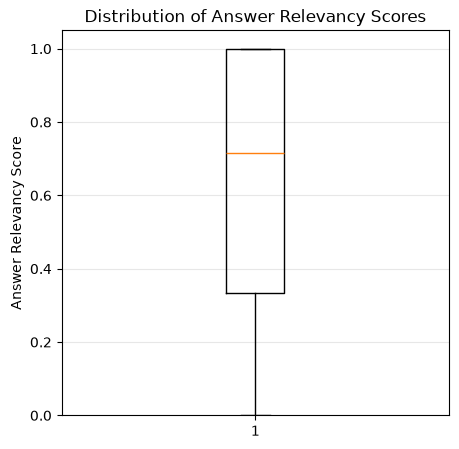

In [114]:
plt.figure(figsize=(5, 5))
plt.boxplot(final_df["relevancy"].dropna())
plt.ylabel("Answer Relevancy Score")
plt.title("Distribution of Answer Relevancy Scores")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)

plt.show()

On the boxplot above, we see that the median relevancy according to the GPT judge-model is equal to aprox 0.7. 75% of the answers have relevancy scores higher or equal to 0.35.  I think it is an acceptale result for my system.

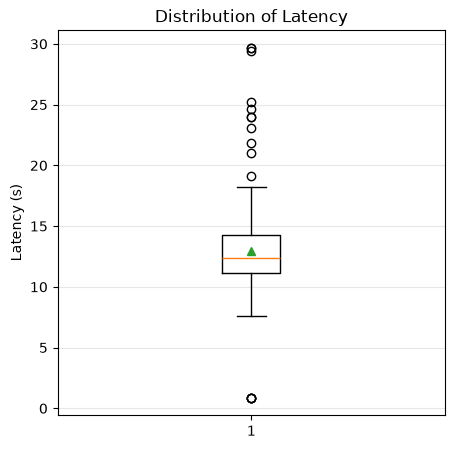

In [131]:
plt.figure(figsize=(5, 5))

plt.boxplot(
    final_df["llama_latency"].dropna(),
    showmeans=True
)

plt.ylabel("Latency (s)")
plt.title("Distribution of Latency")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [132]:
latency = final_df["llama_latency"].dropna()

print(f"Mean: {latency.mean():.2f} s")
print(f"Median: {latency.median():.2f} s")
print(f"P95: {latency.quantile(0.95):.2f} s")

Mean: 12.97 s
Median: 12.41 s
P95: 22.52 s


The mean and median are relatively close, indicating that the typical response time is around 12–13 seconds. The P95 latency indicates that 95% of queries are processed within 22.52 seconds, while approximately 5% take longer. The difference between P95 and P50 (10.11 seconds) suggests that some queries require significantly more processing time.

Earler, I have generated answers using Qwen model and saved the results to the file. I was  measuring the latency for the entire flow. Below is the analisys of Qwen answer generation.

In [139]:
qwen_results = pd.read_csv("full_flow_default_res.csv")
qwen_results.head(3)

,questions,answer,latency
0,What are the main limitations of economic grow...,{'answer': 'The main limitations of economic g...,32.696086
1,What are the main limitations of operating sys...,{'answer': 'The main limitations of operating ...,44.832951
2,How can researchers evaluate optical interfere...,"{'answer': ""Researchers can evaluate optical i...",38.566016


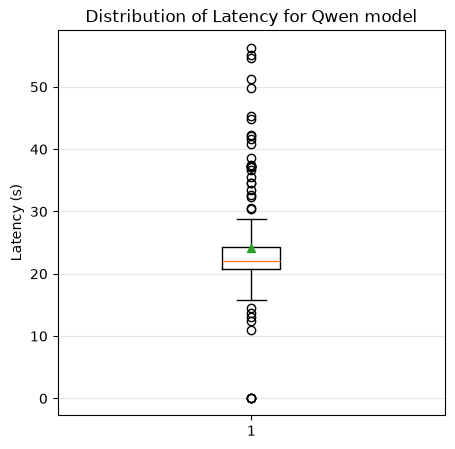

In [140]:
plt.figure(figsize=(5, 5))

plt.boxplot(
    qwen_results["latency"].dropna(),
    showmeans=True
)

plt.ylabel("Latency (s)")
plt.title("Distribution of Latency for Qwen model")
plt.grid(axis="y", alpha=0.3)

plt.show()


We can see that Qwen has taken more time on avarage to return an answer. I am not going to run the evaluation for the Qwen answer relevance, since it might take a long time.